In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report


In [10]:
#load the dataset from local CSV
df = pd.read_csv('bank-full.csv', sep=';')

df['target'] = (df['y'] == 'yes').astype(int)

In [11]:
#experimental design (correct methodology)
#excluding the 'duration' feature to prevent feature leakage.

essential_features = ['age', 'job', 'marital', 'education', 'housing', 'loan', 'poutcome']

x = df[essential_features]
y = df['target']

cat_features = ['job', 'marital', 'education', 'housing', 'loan', 'poutcome']
num_features = ['age']

#data splitting happens before any preprocessing to prevent Train-Test Contamination
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [12]:
#preprocessing and Modeling (ID3 Equivalent Decision Tree)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
])

#using entropy criterion to simulate ID3 Decision Tree algorithm
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='entropy', random_state=42))
])

model.fit(x_train, y_train)
y_pred = model.predict(x_test)

In [13]:
#table
print("Correct Methodology Performance:\n")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Correct Methodology Performance:


Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.96      0.93     10968
           1       0.35      0.18      0.23      1389

    accuracy                           0.87     12357
   macro avg       0.62      0.57      0.58     12357
weighted avg       0.84      0.87      0.85     12357



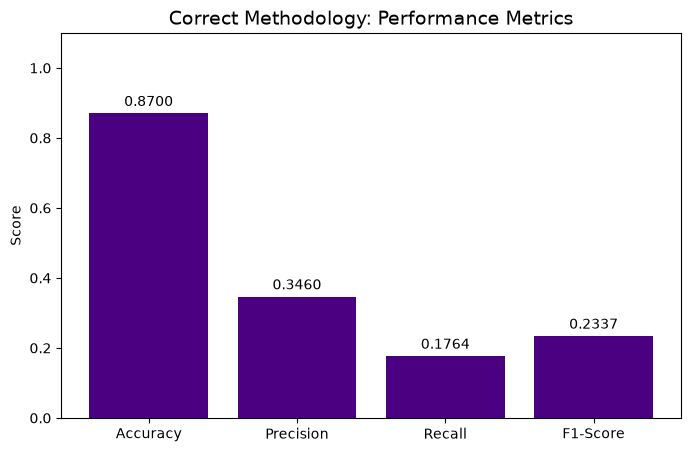

In [14]:
#Graph
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
values = [acc, prec, rec, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values, color=['indigo'])
plt.bar_label(bars, fmt='%.4f', padding=3)
plt.ylim(0, 1.1)
plt.title('Correct Methodology: Performance Metrics', fontsize=14)
plt.ylabel('Score')
plt.show()